# 01. Core Work-Life Indices Harmonization (1999–2024)

This notebook processes historical survey datasets from the Finnish Social Science Data Archive (FSD). It extracts and harmonizes three core indicators across all available survey years (2014–2024):
1. **Work Pace Index** (Work intensity/hurry)
2. **Mental Strain Index** (Psychological stress)
3. **Autonomy Index** (Control over one's work)

In [1]:
# ==========================================
# 1. IMPORTS & CONFIGURATION (2014–2024)
# ==========================================

import glob
import os
import pandas as pd

# Simple dictionary of survey years (2014-2024)
fsd_year_mapping = {
    '3049': 2014,
    '3131': 2015,
    '3220': 2016,
    '3481': 2017,
    '3482': 2018,
    '3493': 2019,
    '3645': 2020,
    '3727': 2021,
    '3784': 2022,
    '3914': 2023,
    '4011': 2024,
}

In [2]:
# ==========================================
# 2. HELPER FUNCTIONS FOR PROCESSING
# ==========================================


# Simple function to find year from filename
def get_year(filename):
  for code, year in fsd_year_mapping.items():
    if code in filename:
      return year
  return None


# Simple function to load CSV with multi-separator fallback
def load_file_safe(file_path):
  for sep in [';', ',']:
    try:
      df = pd.read_csv(
          file_path, sep=sep, low_memory=False, encoding='utf-8-sig'
      )
      if df.shape[1] > 1:
        return df
    except:
      continue
  return None


# Simple function to calculate mean on 1-5 scale
def calculate_mean(column):
  nums = pd.to_numeric(column, errors='coerce')
  valid = nums[(nums >= 1) & (nums <= 5)]
  if len(valid) > 0:
    return round(valid.mean(), 3)
  return None

In [3]:
# ==========================================
# 3. MAIN PROCESSING PIPELINE
# ==========================================

# Empty list to store results
results = []

# Find all CSV files starting with daF inside the 'data' subfolder
all_files = glob.glob(os.path.join('data', 'daF*.csv'))

# Loop through each file
for file_path in all_files:
  filename = os.path.basename(file_path)
  year = get_year(filename)

  # Skip if year is not in our dictionary
  if year is None:
    continue

  # Load the CSV file safely using our function
  df = load_file_safe(file_path)
  if df is None:
    continue

  # Create a lowercase column lookup dictionary to handle changing codes across years
  cols = {c.lower(): c for c in df.columns}

  # Smart column mapping (checks primary and alternative survey codes)
  col_pace = cols.get('k42a') or cols.get('k18_1')
  col_strain = cols.get('k21c_9') or cols.get('k55') or cols.get('k18_4')
  col_autonomy = cols.get('k11a_2') or cols.get('k11_2')

  # Calculate means using safe column existence checks
  pace_mean = (
      calculate_mean(df[col_pace])
      if col_pace and col_pace in df.columns
      else None
  )
  strain_mean = (
      calculate_mean(df[col_strain])
      if col_strain and col_strain in df.columns
      else None
  )
  autonomy_mean = (
      calculate_mean(df[col_autonomy])
      if col_autonomy and col_autonomy in df.columns
      else None
  )

  # Save results as a dictionary and append to list
  results.append({
      'Year': year,
      'Work_Pace': pace_mean,
      'Mental_Strain': strain_mean,
      'Autonomy': autonomy_mean,
  })

print(f'Successfully processed {len(results)} files from data folder!')

Successfully processed 11 files from data folder!


In [4]:
# ==========================================
# 4. DISPLAY & EXPORT RESULTS
# ==========================================

# Convert list of dictionaries into a pandas DataFrame
df_results = pd.DataFrame(results)

# Drop rows without a year and sort by year
df_results = df_results.dropna(subset=['Year'])
df_results = df_results.sort_values('Year')

# Print table to console without row numbers
print(df_results.to_string(index=False))

# Save results to a new CSV file for future plots
df_results.to_csv('work_life_2014_2024.csv', index=False)
print('Done! File saved.')

 Year  Work_Pace  Mental_Strain  Autonomy
 2014      2.136          2.417     2.499
 2015      2.106          2.442     2.523
 2016      2.185          2.431     2.536
 2017      2.160          2.382     2.520
 2018      2.154          2.366     2.456
 2019      2.196          2.326     2.480
 2020      2.179          2.376     2.465
 2021      2.172          2.263     2.486
 2022      2.226          2.236     2.414
 2023      2.323          2.265     2.430
 2024      2.340          2.274     2.437
Done! File saved.


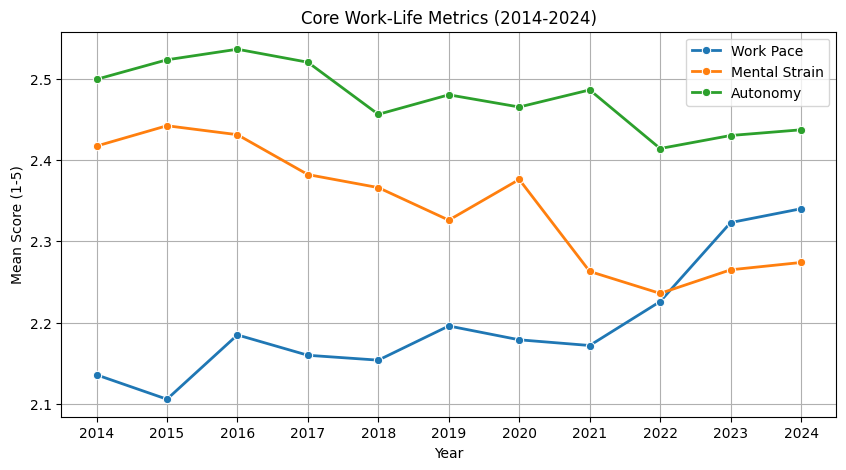

In [5]:
# ==========================================
# 5. PLOT: Core Work-Life Means
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df_plot = pd.read_csv('work_life_2014_2024.csv')

# Set figure size
plt.figure(figsize=(10, 5))

# Plot each line separately (no loops, very simple to understand)
sns.lineplot(
    data=df_plot,
    x='Year',
    y='Work_Pace',
    marker='o',
    linewidth=2,
    label='Work Pace',
)
sns.lineplot(
    data=df_plot,
    x='Year',
    y='Mental_Strain',
    marker='o',
    linewidth=2,
    label='Mental Strain',
)
sns.lineplot(
    data=df_plot,
    x='Year',
    y='Autonomy',
    marker='o',
    linewidth=2,
    label='Autonomy',
)

# Add titles and labels
plt.title('Core Work-Life Metrics (2014-2024)')
plt.xlabel('Year')
plt.ylabel('Mean Score (1-5)')

# Show all years on X-axis
plt.xticks(df_plot['Year'])

# Show legend and grid
plt.legend()
plt.grid(True)

# Save image and show plot
plt.savefig('simple_indices_trend_2014_2024.png', dpi=300)
plt.show()